In [ ]:
import pandas as pd
record = pd.read_csv("../../Data/students_records_messy.csv")
# print(record.shape)
# print(record.dtypes)
# print(record.info())
# print(record[record.duplicated()])

# print(record["age"].isna().sum())
# print(record["score"].isna().sum())
# print(record["city"].isna().sum())
# print(record["join_date"].isna().sum())
# print(record["gender"].isna().sum())
# print(record[record["score"]>0])

record["age"] = pd.to_numeric(record["age"],errors = "coerce")

correct_record = record.dropna(subset =["age"]).copy()

correct_record["score"] = pd.to_numeric(correct_record["score"],errors = "coerce")
correct_record = correct_record[correct_record["score"].notna() & (correct_record["score"]>=0)]

# correct_record = correct_record.rename[

# ]

# print(correct_record["gender"].unique())
correct_record["gender"] = correct_record["gender"].astype(str).str.strip().str.lower()

gender_map = {
    "nan":"Other",
    "female":"Female",
    "f":"Female",
    "male":"Male",
    "man":"Male",
    "other":"Other",
    "m":"Male"
}

correct_record["gender"] = correct_record["gender"].map(gender_map)
correct_record["gender"] = correct_record["gender"].fillna("Other")
# print(correct_record["gender"].unique())

print(correct_record["city"].unique())

correct_record["city"] = correct_record["city"].astype(str).str.strip().str.title()
correct_record["city"] = correct_record["city"].replace(
    ["Nan"],"Unknown"
)
correct_record["city"] = correct_record["city"].fillna("Unknown")

correct_record["join_date"] = pd.to_datetime(correct_record["join_date"],format = "mixed",errors = "coerce", dayfirst = True)

correct_record = correct_record.drop_duplicates()

print(correct_record)

def schema_check(df):
    assert df['age'].dtype != object, "age is not numeric!"
    assert df['score'].dtype != object, "score is not numeric!"
    assert df['student_id'].duplicated().sum() == 0, "Duplicate student_ids found!"
    assert df.duplicated().sum() == 0, "Duplicate rows still exist!"
    print("Schema check passed.")

schema_check(correct_record)

<StringArray>
['Chandigarh', 'Lucknow', 'Mumbai', nan, 'Delhi', 'Pune']
Length: 6, dtype: str
     student_id         name   age  score  gender        city  join_date  \
0           359  Student_359  15.0   73.2   Other  Chandigarh 2021-03-24   
1           339  Student_339  17.0   19.2  Female     Lucknow 2021-12-16   
2           299  Student_299  17.0   75.5  Female  Chandigarh 2020-06-18   
4           421  Student_421  24.0   13.7  Female  Chandigarh 2022-03-25   
5           405  Student_405  19.0   85.3   Other      Mumbai 2019-01-26   
..          ...          ...   ...    ...     ...         ...        ...   
501         408  Student_408  16.0   29.9   Other  Chandigarh 2023-01-15   
502         212  Student_212  22.0   14.5    Male     Unknown        NaT   
505          26   Student_26  21.0   39.4    Male        Pune 2019-03-08   
506         197  Student_197  18.0   98.0  Female  Chandigarh 2023-01-09   
507         176  Student_176  19.0   80.1    Male     Lucknow 2022-05-

In [118]:
import pandas as pd
air_quality_no2 = pd.read_csv("air_quality_no2_long.csv",parse_dates = True)
air_quality_no2 = air_quality_no2[["date.utc","location","parameter","value"]]
air_quality_no2.head()

air_quality_pm25 = pd.read_csv("air_quality_pm25_long.csv")
air_quality_pm25 = air_quality_pm25[["date.utc","location","parameter","value"]]
air_quality_pm25.head()

air_quality = pd.concat([air_quality_no2,air_quality_pm25],axis = 0)
air_quality.head()

print("Shape of air_quality_no2 table is :",air_quality_no2.shape)
print("Shape of air_quality_pm25 table is :",air_quality_pm25.shape)
print("Shape of the resulting table air_quality is :",air_quality.shape)

air_quality_sorted = air_quality.sort_values("date.utc",ascending = False)
air_quality_sorted.head()


air_quality = pd.concat([air_quality_no2,air_quality_pm25],keys = ["PM25","NO2"])
air_quality.head()

stations_coord = pd.read_csv("../../Data/air_quality_stations.csv")
stations_coord.head()

merged = pd.merge(air_quality,stations_coord, how = "outer", on = "location")
merged = pd.merge(air_quality,stations_coord, how = "inner", on = "location")
merged = pd.merge(air_quality,stations_coord, how = "left", on = "location")
merged = pd.merge(air_quality,stations_coord, how = "right", on = "location")
merged.head()

Shape of air_quality_no2 table is : (2068, 4)
Shape of air_quality_pm25 table is : (1110, 4)
Shape of the resulting table air_quality is : (3178, 4)


,date.utc,location,parameter,value,coordinates.latitude,coordinates.longitude
0,NaN,BELAL01,NaN,NaN,51.23619,4.38522
1,NaN,BELHB23,NaN,NaN,51.17030,4.34100
2,NaN,BELLD01,NaN,NaN,51.10998,5.00486
3,NaN,BELLD02,NaN,NaN,51.12038,5.02155
4,NaN,BELR833,NaN,NaN,51.32766,4.36226


In [74]:
import pandas as pd
df = pd.read_csv("df.csv",index_col = 0)
print(df.pivot_table(
    index = "date",
    columns = "city",
    values = "value",
    aggfunc = "mean"
))
# print(df.melt(id_vars="date"))

Empty DataFrame
Columns: []
Index: []


In [ ]:
import pandas as pd
titanic = pd.read_csv("../../datatitanic.csv")
print(titanic["Age"].mean())
print(titanic[["Age","Fare"]].median())
print(titanic.agg(
    {
        "Age": ["mean","median","skew","max","min"],
        "Fare": ["mean","median","skew","max","min"],
    }
))
avg_age = titanic[["Sex","Age"]].groupby("Sex").mean()
avg_age = titanic.groupby("Sex")["Age"].mean()
print(avg_age)
print(titanic.groupby("Sex").mean(numeric_only = True))
print(titanic.groupby(["Sex","Pclass"])["Fare"].mean())
print(titanic.groupby("Pclass")["Pclass"].count())
print(titanic.sort_values(by=["Age","PassengerId"], ascending = [False,True]).head())


              Age                                                            \
Age         22.00  38.00  26.00  35.00        NaN 54.00 2.00   27.00  14.00   
Sex          male female female female  male male  male  male female female   
PassengerId                                                                   
1            22.0    NaN    NaN    NaN   NaN  NaN   NaN   NaN    NaN    NaN   
2             NaN   38.0    NaN    NaN   NaN  NaN   NaN   NaN    NaN    NaN   
3             NaN    NaN   26.0    NaN   NaN  NaN   NaN   NaN    NaN    NaN   
4             NaN    NaN    NaN   35.0   NaN  NaN   NaN   NaN    NaN    NaN   
5             NaN    NaN    NaN    NaN  35.0  NaN   NaN   NaN    NaN    NaN   
...           ...    ...    ...    ...   ...  ...   ...   ...    ...    ...   
887           NaN    NaN    NaN    NaN   NaN  NaN   NaN   NaN    NaN    NaN   
888           NaN    NaN    NaN    NaN   NaN  NaN   NaN   NaN    NaN    NaN   
889           NaN    NaN    NaN    NaN   NaN  NaN   

In [53]:
import pandas as pd
air_quality = pd.read_csv("air_quality.csv",index_col = 0,parse_dates = True)
# air_quality.head()
air_quality["london_mg_per_cubic"] = air_quality["station_london"] * 1.882
# air_quality.head()
air_quality["paris_vs_antwerp"] = (
    air_quality["station_paris"] / air_quality["station_antwerp"]
)
air_quality.head()
renamed_air_quality = air_quality.rename(
    columns = {
        "station_antwerp":"kanpur",
        "station_london":"lucknow",
        "station_paris":"delhi",
        "london_mg_per_cubic":"lko_mg_per_cubic",
        "paris_vs_antwerp":"lucknow_vs_kanpur",
    }
)
renamed_air_quality = renamed_air_quality.rename(columns = str.upper)
renamed_air_quality


,KANPUR,DELHI,LUCKNOW,LKO_MG_PER_CUBIC,LUCKNOW_VS_KANPUR
datetime,,,,,
2019-05-07 02:00:00,NaN,NaN,23.0,43.286,NaN
2019-05-07 03:00:00,50.5,25.0,19.0,35.758,0.495050
2019-05-07 04:00:00,45.0,27.7,19.0,35.758,0.615556
2019-05-07 05:00:00,NaN,50.4,16.0,30.112,NaN
2019-05-07 06:00:00,NaN,61.9,NaN,NaN,NaN
...,...,...,...,...,...
2019-06-20 22:00:00,NaN,21.4,NaN,NaN,NaN
2019-06-20 23:00:00,NaN,24.9,NaN,NaN,NaN
2019-06-21 00:00:00,NaN,26.5,NaN,NaN,NaN


                     station_paris  station_london
datetime                                          
2019-05-07 02:00:00            NaN            23.0
2019-05-07 03:00:00           25.0            19.0
2019-05-07 04:00:00           27.7            19.0
2019-05-07 05:00:00           50.4            16.0
2019-05-07 06:00:00           61.9             NaN


array([<Axes: xlabel='datetime'>, <Axes: xlabel='datetime'>,
       <Axes: xlabel='datetime'>], dtype=object)

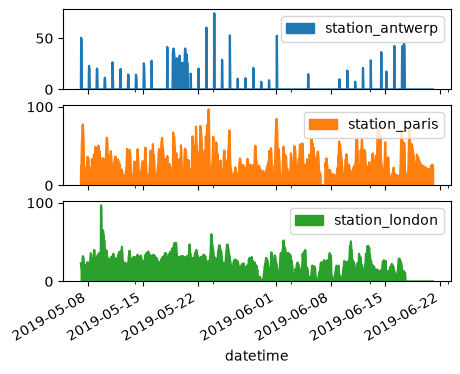

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
air_quality = pd.read_csv("air_quality.csv",index_col = 0,parse_dates = True)
print(air_quality.iloc[0:5,1:3])
air_quality.plot()
# air_quality["station_paris"].plot()
plt.show()
air_quality.plot.scatter(x = "station_paris", y = "station_london", alpha = 0.5)
plt.show()
air_quality.plot.box()
air_quality.plot.area(figsize = (12,4), subplots = True)

   PassengerId  Survived  Pclass
0            1         0       3
1            2         1       1
2            3         1       3
3            4         1       1
4            5         0       3


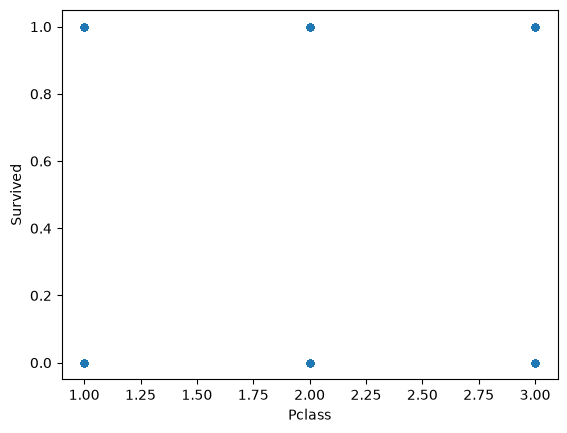

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
titanic = pd.read_csv("../../datatitanic.csv")
# print(titanic)
# print(titanic.head(10))
# print(titanic.tail(10))
# print(titanic.dtypes)
# print(titanic.to_excel("Titanic.xlsx",sheet_name = "Passengers",index = False))
# titanic = pd.read_excel("Titanic.xlsx",sheet_name = "Passengers")
# # print(titanic.head())
# print(titanic.info())
age = titanic["Age"]
# print(age.head())
age_sex = titanic[["Age","Sex"]]
# print(age_sex.head())
# print(type(titanic[["Age","Sex"]]))
# print(type(titanic["Age"]))
buddhe = titanic[titanic["Age"] > 70]
# print(buddhe)
class3 = titanic[titanic["Pclass"].isin([3])]
# print(class3)
age_not_known = titanic[titanic["Age"].isna()]
# print(age_not_known.head())
age_known = titanic[titanic["Age"].notna()]
# print(age_known.head())
adult_names = titanic.loc[titanic["Age"]>18,"Name"]
# print(adult_names)
print(titanic.iloc[0:5, 0:3])

titanic.plot.scatter(x = "Pclass",y = 1,alpha = 0.7)
plt.show()

In [16]:
import pandas as pd
titanic = pd.DataFrame(
    {
        "Name": [ "Lat","Pull","Down"],
        
        "Salaries": [100000,200000,500000]
    }
)
print(titanic.describe())

            Salaries
count       3.000000
mean   266666.666667
std    208166.599947
min    100000.000000
25%    150000.000000
50%    200000.000000
75%    350000.000000
max    500000.000000


In [ ]:
import pandas as pd
titanic = pd.DataFrame(
    {
        "Name": [
            "Motu",
            "Patlu",
            "Chodu",
        ],
        "Age": [18,15,20],
        "Sex": ["Male","Male","Hinjda"],
        "MORE": [12,45,78]
    }
    
)
print(titanic)
print(titanic.max())
ages = pd.Series([12,45,78],name = "Age")
print(ages.max())

Name    zhodu
Age        20
Sex      Male
MORE       78
dtype: object
78
